# Tagging Open-Ended Survey Feedback into Themes

**Problem:** Field surveys collect hundreds of free-text comments from outlet owners. Reading and tagging them by hand
takes days, so they usually get ignored.

**Approach:** turn comments into TF-IDF vectors → pick the number of themes with silhouette scores → cluster with K-Means →
name each cluster from its top terms → check the result against a hand-labelled set → report themes by town.

This is the reproducible, non-LLM baseline for the LLM-assisted tagging I piloted. It's cheap, explainable and fast,
and it gives an LLM-based approach something to beat.

> Data is **synthetic** (`src/generate_data.py`). The `true_theme` column is used **only** for evaluation, never for training.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import TruncatedSVD

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
Path("images").mkdir(exist_ok=True)

fb = pd.read_csv("data/outlet_feedback.csv")
print(fb.shape)
fb.sample(8, random_state=3)[["town", "comment"]]

(640, 4)


,town,comment
81,Komani,The commission is too small fr the work.
170,Komani,The device prints slips badly and machine need...
155,Lady Frere,We ran out of sim cards last week and out of s...
509,Komani,Give us branded umbrella and banner and ned br...
215,Cofimvaba,Stock delivery is late and give us branded umb...
551,Cofimvaba,The printer paper runs out on the device and t...
107,Whittlesea,Customers complain data is slow here and the c...
442,Lady Frere,Payment for sims sold came late. we are losing...


## 1. Vectorise

In [2]:
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X = vec.fit_transform(fb.comment)
print(f"{X.shape[0]} comments x {X.shape[1]} terms")

640 comments x 327 terms


## 2. How many themes? Silhouette score across k

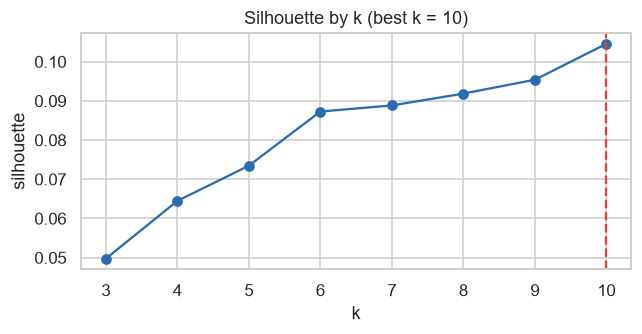

In [3]:
scores = {}
for k in range(3, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    scores[k] = silhouette_score(X, km.labels_)
best_k = max(scores, key=scores.get)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(list(scores), list(scores.values()), marker="o", color="#2b6cb0")
ax.axvline(best_k, color="#e53e3e", ls="--"); ax.set(title=f"Silhouette by k (best k = {best_k})", xlabel="k", ylabel="silhouette")
plt.tight_layout(); plt.savefig("images/silhouette.png", bbox_inches="tight"); plt.show()

## 3. Cluster and read the top terms

In [4]:
km = KMeans(n_clusters=best_k, n_init=50, random_state=0).fit(X)
fb["cluster"] = km.labels_
terms = np.array(vec.get_feature_names_out())
top_terms = {c: ", ".join(terms[np.argsort(km.cluster_centers_[c])[::-1][:8]]) for c in range(best_k)}
pd.DataFrame({"size": fb.cluster.value_counts().sort_index(), "top_terms": pd.Series(top_terms)})

,size,top_terms
0,95,"commission, work, small, late, commission smal..."
1,57,"signal, rains, signal rains, calls, calls drop..."
2,91,"stock, month, sim, supplier, comes, supplier c..."
3,96,"help, training, need, visits help, rep visits,..."
4,64,"branding, road, people road, people, need bran..."
5,39,"network, dropping afternoon, keeps dropping, d..."
6,32,"finish, finish quickly, starter, packs, quickl..."
7,70,"device, slow, printer, paper runs, printer pap..."
8,54,"terminal, software, software update, update, u..."
9,42,"banner, umbrella banner, umbrella, branded, br..."


An analyst names each cluster from its top terms. This is the step that stays human, and the step an LLM can speed up.
The mapping below is written from the table above, the way you would in practice.

In [5]:
KEYWORDS = {  # theme name -> words that identify it in the top-terms list
    "Network quality": ["signal", "network", "slow", "drop"],
    "SIM & stock supply": ["stock", "sim cards", "starter", "supplier"],
    "Commission & payment": ["commission", "payment", "paid"],
    "Terminal & device issues": ["terminal", "machine", "device", "printer"],
    "Branding & visibility": ["branding", "board", "poster", "signage", "banner"],
    "Training & support": ["training", "help", "support", "rep", "helpline"],
}
def name_cluster(c):
    tt = top_terms[c]
    hits = {theme: sum(tt.count(w) for w in words) for theme, words in KEYWORDS.items()}
    return max(hits, key=hits.get)

fb["theme"] = fb.cluster.map({c: name_cluster(c) for c in range(best_k)})
fb[["comment", "theme"]].sample(10, random_state=11)

,comment,theme
129,We ran out of sim cards last week and stock de...,SIM & stock supply
544,Commission is paid late. it has been like this...,Commission & payment
179,Rep never visits to help and the printer paper...,Terminal & device issues
480,We ran out of sim cards last week and starter ...,SIM & stock supply
96,Need more sim stock every month and supplier o...,SIM & stock supply
220,Nobody showed me how to regster a sim and the ...,Training & support
432,Supplier only comes once a month with stock an...,SIM & stock supply
274,Commission is paid late. it has been like this...,Commission & payment
165,Network coverage is bad in this area and custo...,Network quality
109,Supplier only comes once a month with stock. t...,SIM & stock supply


## 4. How good is it? Compare with the hand-labelled themes

Agreement with hand labels: 88.0%   |   Adjusted Rand Index: 0.59


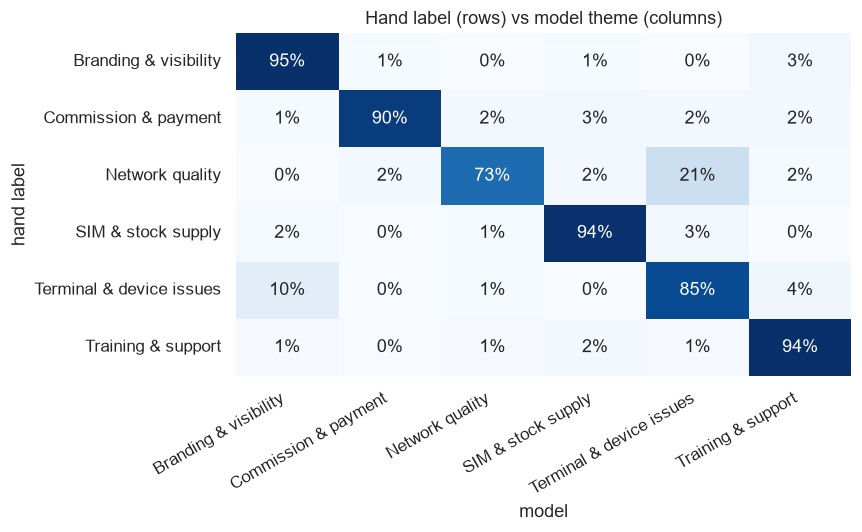

In [6]:
acc = (fb.theme == fb.true_theme).mean()
ari = adjusted_rand_score(fb.true_theme, fb.cluster)
print(f"Agreement with hand labels: {acc:.1%}   |   Adjusted Rand Index: {ari:.2f}")

cm = pd.crosstab(fb.true_theme, fb.theme, normalize="index")
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(cm, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Hand label (rows) vs model theme (columns)", xlabel="model", ylabel="hand label")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.savefig("images/confusion.png", bbox_inches="tight"); plt.show()

In [7]:
# Where does it go wrong? Mostly comments that mention two themes
wrong = fb[fb.theme != fb.true_theme]
print(f"{len(wrong)} disagreements; share containing ' and ': {wrong.comment.str.contains(' and ').mean():.0%}")
wrong[["comment", "true_theme", "theme"]].head(6)

77 disagreements; share containing ' and ': 69%


,comment,true_theme,theme
11,Commission is paid late and payment for sims s...,Commission & payment,SIM & stock supply
12,Please paint the wall with branding and need t...,Branding & visibility,Training & support
42,Slow internet for customers and need training ...,Network quality,Training & support
46,Slow internet for customers and support takes ...,Network quality,Training & support
53,Machine needs to be fixed and the airtime mach...,Terminal & device issues,Branding & visibility
69,The airtime machine is offline often and suppo...,Terminal & device issues,Training & support


## 5. 2-D view of the clusters

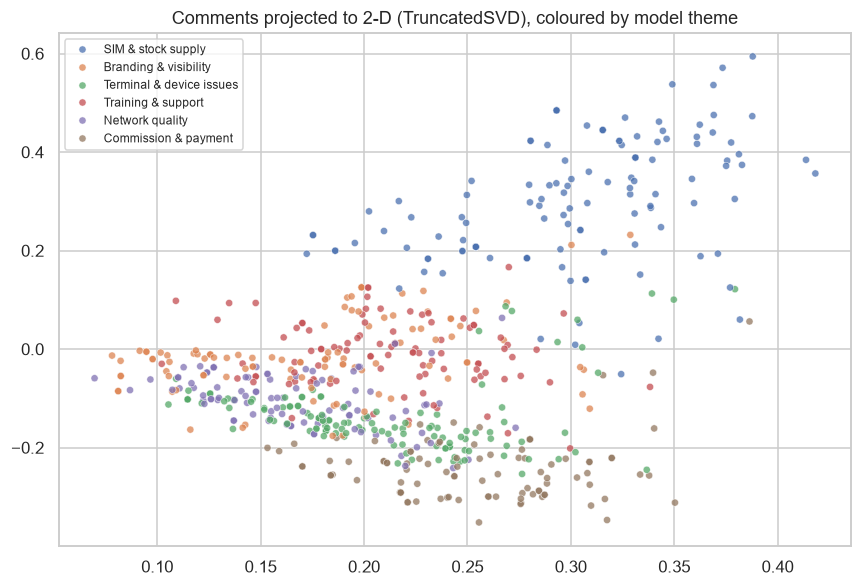

In [8]:
xy = TruncatedSVD(n_components=2, random_state=0).fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=fb.theme, s=22, alpha=0.75, ax=ax)
ax.set(title="Comments projected to 2-D (TruncatedSVD), coloured by model theme", xlabel="", ylabel="")
ax.legend(fontsize=8, loc="best"); plt.tight_layout(); plt.savefig("images/clusters_2d.png", bbox_inches="tight"); plt.show()

## 6. The business read-out: what are outlets telling us, by town?

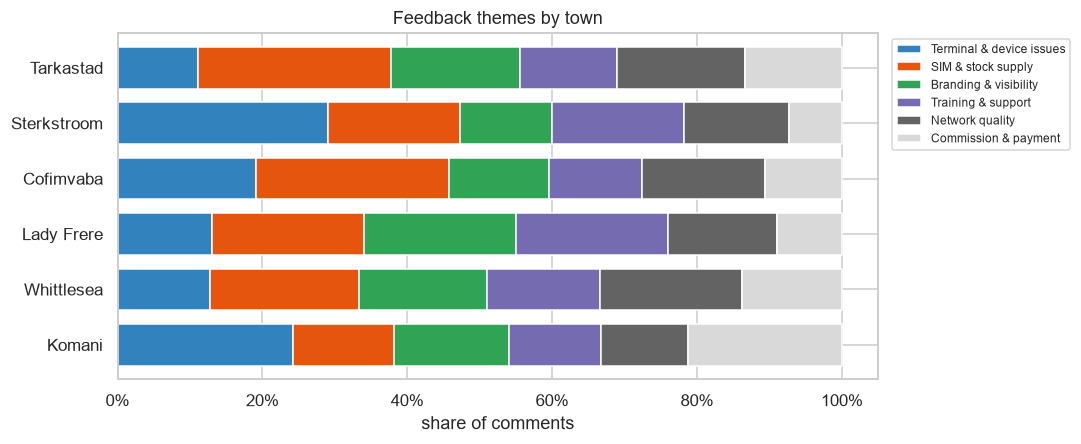

Overall theme share:
theme
Terminal & device issues    19%
SIM & stock supply          19%
Branding & visibility       17%
Training & support          15%
Network quality             15%
Commission & payment        15%
Name: proportion, dtype: str


In [9]:
mix = pd.crosstab(fb.town, fb.theme, normalize="index")
order = fb.theme.value_counts().index
mix = mix[order].loc[fb.town.value_counts().index]

fig, ax = plt.subplots(figsize=(10, 4.2))
mix.plot(kind="barh", stacked=True, ax=ax, colormap="tab20c", width=0.75)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set(title="Feedback themes by town", xlabel="share of comments", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig("images/themes_by_town.png", bbox_inches="tight"); plt.show()

overall = fb.theme.value_counts(normalize=True).map("{:.0%}".format)
print("Overall theme share:"); print(overall)

In [10]:
fb[["response_id", "town", "comment", "theme"]].to_csv("data/tagged_feedback.csv", index=False)
print("Saved data/tagged_feedback.csv")

Saved data/tagged_feedback.csv


## Takeaways
- An unsupervised baseline **agrees with hand labels on ~88% of comments** and runs in seconds, where manual tagging takes days.
- **SIM & stock supply is the top issue outside Komani** (21–27% of comments in Cofimvaba, Tarkastad, Lady Frere and Whittlesea). **Komani skews to commission and terminal issues.** Different towns need different actions.
- **Known blind spot:** the model *undercounts* network complaints (15% vs 20% in the hand labels), because the word "slow" pulls some network comments into the device cluster. An analyst should check this before reporting, and a domain-tuned term list would fix it.
- Most remaining errors are **comments that raise two issues**. The next step is multi-label tagging, where an LLM can assign several themes per comment. This baseline is the benchmark it has to beat.